# Chapitre 7 - Exercices 7.5 à 7.8

Ce notebook traite les exercices sur le write skew et la sérialisabilité :

- **7.5** : un atelier à places limitées ; quand `SELECT ... FOR UPDATE` suffit-il, et
  comment matérialiser le conflit ?
- **7.6** : graphes de précédence, et preuve expérimentale que 2PL ne produit que des
  exécutions sérialisables ;
- **7.7** : dimensionner une base à exécution en série partitionnée ;
- **7.8** : 2PL contre SSI selon la part de transactions en lecture seule (mini-lab).

In [1]:
import itertools

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from ddia import transactions as tr
from ddia.transactions import (R, W, S, SFU, RFU, INC, run, plot_history, plot_precedence,
                               precedence_graph, is_serializable, simulate_load, LEVEL_LABELS)
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## Exercice 7.5 : un atelier à places limitées

**Énoncé.** Un atelier accepte au plus 3 inscrits. L'inscription compte les inscrits
(`SELECT ... WHERE atelier = 7`), puis insère une ligne si le compte est inférieur à 3.

1. Sous snapshot isolation, combien d'inscrits peut-on obtenir au pire si 4 personnes
   s'inscrivent simultanément alors que l'atelier est vide ?
2. On ajoute `FOR UPDATE` à la requête de comptage, en *read committed*. Montrer que cela
   suffit quand il y a déjà au moins un inscrit, mais pas quand l'atelier est vide.
   Expliquer.
3. Proposer une matérialisation du conflit et la vérifier.

**Rappels.** Write skew, fantômes, `FOR UPDATE` et matérialisation des conflits (cours 3,
sections 7 à 9 ; sections *Phantoms causing write skew* et *Materializing conflicts*).

**Solution.**

*1.* Les 4 transactions comptent 0 dans leur instantané et insèrent chacune une ligne
différente : **4 inscrits**, quel que soit le nombre de places. Avec $n$ inscriptions
simultanées, on peut atteindre $n$ inscrits.

*2.* `FOR UPDATE` verrouille les lignes **trouvées**. S'il y a déjà un inscrit, toutes
les transactions trouvent sa ligne et veulent la verrouiller : elles passent une par une
(la seconde attend la première ; en *read committed*, elle relit ensuite la dernière
version validée et recompte). Si l'atelier est vide, la requête ne trouve rien, aucun
verrou n'est pris : c'est le fantôme. (Subtilité : même avec un inscrit, le compte relu
après l'attente n'inclut la nouvelle ligne que si le moteur réévalue la requête ; notre
moteur, comme PostgreSQL en *read committed*, relit seulement les lignes verrouillées,
d'où l'intérêt de vérifier expérimentalement.)

*3.* On matérialise une ligne `atelier:7` (un compteur de places) que toute inscription
verrouille (`SELECT ... FOR UPDATE` puis incrément) : le conflit porte alors sur une ligne
qui existe toujours. Encore mieux : un incrément conditionnel atomique.

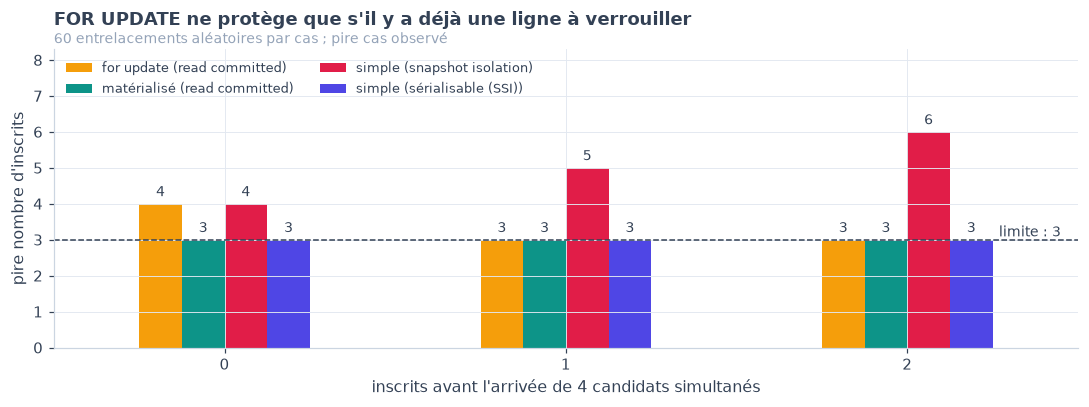

déjà_inscrits,0,1,2
stratégie,,,
for update (read committed),4,3,3
matérialisé (read committed),3,3,3
simple (snapshot isolation),4,5,6
simple (sérialisable (SSI)),3,3,3


In [2]:
atelier7 = lambda k, v: k.startswith("ins:")


def inscription(qui, for_update=False, materialise=False):
    def prog():
        if materialise:
            n = yield RFU("atelier:7")
            if n < 3:
                yield W("atelier:7", n + 1)
                yield W(f"ins:{qui}", True)
            return
        req = SFU(atelier7, "compte") if for_update else S(atelier7, "compte")
        ins = yield req
        if len(ins) < 3:
            yield W(f"ins:{qui}", True)
    return prog


def experience(n_deja, mode, level, n_cand=4, essais=60, seed=0):
    g = np.random.default_rng(seed)
    pire = 0
    for _ in range(essais):
        init = {f"ins:ancien{i}": True for i in range(n_deja)}
        init["atelier:7"] = n_deja
        progs = {f"c{i}": inscription(f"c{i}", mode == "for update", mode == "matérialisé") for i in range(n_cand)}
        ordre = list(g.permutation([f"c{i}" for i in range(n_cand) for _ in range(4)]))
        r = run(init, progs, ordre, level=level)
        pire = max(pire, sum(1 for k in r.final if k.startswith("ins:")))
    return pire


lignes = []
for n_deja in [0, 1, 2]:
    for mode, level in [("simple", "snapshot"), ("for update", "read_committed"), ("matérialisé", "read_committed"),
                        ("simple", "serializable_ssi")]:
        lignes.append(dict(déjà_inscrits=n_deja, stratégie=f"{mode} ({LEVEL_LABELS[level]})",
                           pire_nombre_d_inscrits=experience(n_deja, mode, level)))
tab = pd.DataFrame(lignes).pivot(index="stratégie", columns="déjà_inscrits", values="pire_nombre_d_inscrits")
ax = tab.T.plot.bar(figsize=(10, 3.8), color=[AMBER, TEAL, ROSE, INDIGO], rot=0)
ax.set_ylim(0, 8.3)
ax.axhline(3, color=SLATE, ls="--", lw=1)
ax.text(2.45, 3.1, "limite : 3", fontsize=9, color=SLATE, ha="right")
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("inscrits avant l'arrivée de 4 candidats simultanés")
ax.set_ylabel("pire nombre d'inscrits")
ax.set_title("FOR UPDATE ne protège que s'il y a déjà une ligne à verrouiller")
subtitle(ax, "60 entrelacements aléatoires par cas ; pire cas observé")
ax.legend(fontsize=8.5, loc="upper left", ncol=2)
plt.tight_layout(); plt.show()
tab

Les mesures confirment l'analyse : sans protection, 4 candidats donnent jusqu'à 4 + (déjà
inscrits) lignes ; `FOR UPDATE` dépasse la limite quand l'atelier est vide (aucun verrou
posé), et fonctionne dès qu'une ligne existe ; la matérialisation (verrou sur la ligne
`atelier:7`) et SSI respectent toujours la limite.

> **À retenir.** `FOR UPDATE` protège une décision fondée sur des lignes **qui existent** ;
> une décision fondée sur une **absence** exige un verrou de prédicat (sérialisable) ou
> une ligne matérialisée.

## Exercice 7.6 : graphes de précédence et 2PL

**Énoncé.**

1. Construire à la main le graphe de précédence de l'historique
   `r1(x) r2(y) w2(x) r3(x) w1(y) w3(z) c1 c2 c3` (on suppose x, y, z initialisés par une
   transaction antérieure). Est-il sérialisable par conflits ? Si oui, dans quel ordre ?
2. Engendrer 400 entrelacements aléatoires de 3 transactions lire-modifier-écrire sur 3
   clés, **sans isolation**. Quelle fraction est sérialisable (par force brute) ?
   sérialisable par conflits (graphe acyclique) ?
3. Exécuter les mêmes entrelacements sous 2PL et vérifier que **toutes** les exécutions
   validées ont un graphe acyclique, compatible avec l'ordre de validation.

**Rappels.** Graphe de précédence (arcs wr, ww, rw) et sérialisabilité par conflits ;
point de verrouillage de 2PL (cours 4, sections 1 et 5 ; section *Serializability*).

**Solution.**

*1.* Conflits (même objet, au moins une écriture, transactions différentes), dans l'ordre
de l'historique :

- `r1(x)` avant `w2(x)` : arc **1 → 2** (rw) ;
- `w2(x)` avant `r3(x)` : arc **2 → 3** (wr) ;
- `r2(y)` avant `w1(y)` : arc **2 → 1** (rw) ;
- `r1(x)` et `r3(x)` ne sont pas en conflit (deux lectures) ; `w3(z)` ne croise personne.

Les arcs 1 → 2 et 2 → 1 forment un **cycle** : l'historique n'est pas sérialisable par
conflits (T1 doit précéder T2 parce qu'elle a lu l'ancien x, et le suivre parce que T2 a
lu l'ancien y : c'est un write skew).

*2. et 3.* Code ci-dessous. Attendu : une petite fraction sérialisable sans isolation, la
sérialisabilité par conflits étant légèrement plus stricte que la force brute ; sous 2PL,
100 % des exécutions validées sont sérialisables par conflits.

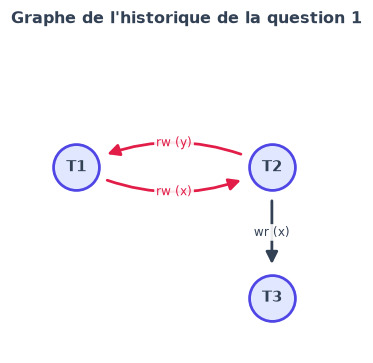

cycles : [['T2', 'T1']]


In [3]:
def t1():
    yield R("x")
    yield W("y", 1)


def t2():
    yield R("y")
    yield W("x", 2)


def t3():
    yield R("x")
    yield W("z", 3)


r = run({"x": 0, "y": 0, "z": 0}, {"T1": t1, "T2": t2, "T3": t3},
        ["T1", "T2", "T2", "T3", "T1", "T3", "T1", "T2", "T3"], level="none")
g = precedence_graph(r)
fig, ax = plt.subplots(figsize=(5, 3.4))
plot_precedence(g, ax=ax, title="Graphe de l'historique de la question 1",
                pos={"T1": (-0.9, 0.3), "T2": (0.9, 0.3), "T3": (0.9, -0.9)})
plt.tight_layout(); plt.show()
print("cycles :", list(nx.simple_cycles(g)))

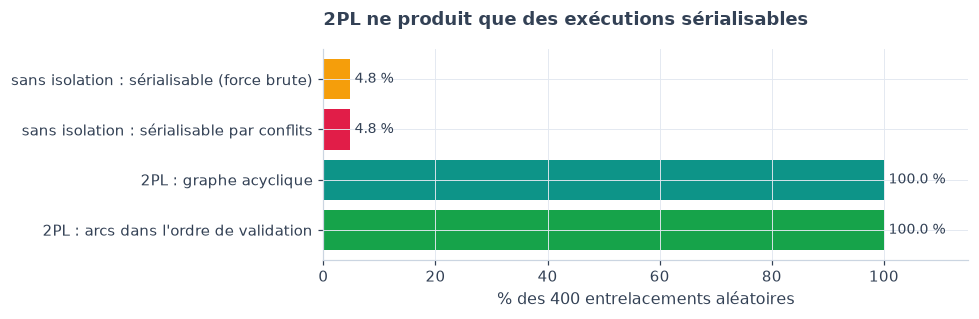

In [4]:
def rmw(k1, k2):
    def prog():
        a = yield R(k1)
        yield W(k1, a + 1)
        b = yield R(k2)
        yield W(k2, b * 2)
    return prog


g_rng = np.random.default_rng(6)
stats = {"brute": 0, "conflits": 0, "2pl_acyclique": 0, "2pl_ordre": 0, "2pl_runs": 0}
N = 400
for _ in range(N):
    progs = {}
    for t in ["A", "B", "C"]:
        k1, k2 = g_rng.choice(["x", "y", "z"], 2, replace=False)
        progs[t] = rmw(str(k1), str(k2))
    ordre = list(g_rng.permutation([t for t in "ABC" for _ in range(5)]))
    init = {"x": 1, "y": 1, "z": 1}
    r0 = run(init, progs, ordre, level="none")
    stats["brute"] += is_serializable(r0, init, progs) is not None
    stats["conflits"] += nx.is_directed_acyclic_graph(precedence_graph(r0))
    r2 = run(init, progs, ordre, level="serializable_2pl")
    g2 = precedence_graph(r2)
    stats["2pl_runs"] += 1
    stats["2pl_acyclique"] += nx.is_directed_acyclic_graph(g2)
    ordre_commit = sorted(r2.committed, key=lambda n: next(t.commit_seq for t in r2.engine.txs.values()
                                                            if t.name == n and t.status == "committed"))
    stats["2pl_ordre"] += all(ordre_commit.index(u) < ordre_commit.index(v) for u, v in g2.edges())
res6 = pd.Series({"sans isolation : sérialisable (force brute)": stats["brute"] / N,
                  "sans isolation : sérialisable par conflits": stats["conflits"] / N,
                  "2PL : graphe acyclique": stats["2pl_acyclique"] / N,
                  "2PL : arcs dans l'ordre de validation": stats["2pl_ordre"] / N})
fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(res6.index, res6.values * 100, color=[AMBER, ROSE, TEAL, GREEN])
annotate_bars(ax, "{:.1f} %")
ax.invert_yaxis()
ax.set_xlim(0, 115)
ax.set_xlabel("% des 400 entrelacements aléatoires")
ax.set_title("2PL ne produit que des exécutions sérialisables")
plt.tight_layout(); plt.show()

Sans isolation, moins de 5 % des entrelacements sont sérialisables. Ici, force brute et
graphe de précédence donnent exactement la même fraction ; en général, la
sérialisabilité par conflits est un peu plus stricte (un entrelacement peut, par chance,
donner le même résultat qu'un ordre série malgré un cycle, par exemple quand une écriture
réécrit la même valeur). Sous 2PL,
100 % des graphes sont acycliques **et** tous les arcs vont dans le sens de l'ordre de
validation : c'est exactement la preuve du cours 4 (le point de verrouillage, juste avant
la validation, ordonne les transactions).

> **À retenir.** Un cycle dans le graphe de précédence est la signature d'une anomalie ;
> 2PL l'interdit structurellement, en ordonnant les transactions par leur point de
> verrouillage.

## Exercice 7.7 : dimensionner une base à exécution en série

**Énoncé.** Un site marchand vise 20 000 transactions par seconde en pointe. Chaque
transaction est une procédure stockée de 30 µs en mémoire quand elle est locale à
une partition ; une fraction $f$ touche plusieurs partitions et occupe alors tous les fils
pendant 2 ms.

1. Combien de partitions faut-il si $f = 0$ ? si $f = 1\,\%$ ? si $f = 5\,\%$ ?
2. Quelle fraction $f$ maximale permet d'atteindre l'objectif, même avec une infinité de
   partitions ?
3. Vérifier le modèle par une petite simulation (affectation aléatoire des transactions,
   calcul de l'occupation de chaque fil).

**Rappels.** Débit maximal $T = 1 / \big((1-f)\,t_s/n + f\,t_x\big)$ (cours 4,
section 4 ; section *Partitioning* de *Actual Serial Execution*).

**Solution.**

*1.* Il faut $T \ge 20\,000$, soit $(1-f)\,t_s/n + f\,t_x \le 50\,\mu s$.

- $f = 0$ : $30/n \le 50$, donc **1 seul fil** suffit (33 000 tx/s).
- $f = 1\,\%$ : $f\,t_x = 20\,\mu s$, il reste $30\,\mu s$ pour
  $0{,}99 \times 30/n$, soit $n \ge 0{,}99$ : **1 fil** (juste : 20 200 tx/s).
- $f = 5\,\%$ : $f\,t_x = 100\,\mu s > 50\,\mu s$ : **impossible**, quel que soit $n$.

*2.* Même avec $n \to \infty$, il faut $f\,t_x \le 50\,\mu s$, soit
$f \le 2{,}5\,\%$. En pratique, avec une marge (fils occupés à 70 %), $f$ doit rester
sous 1,75 %, et l'effort doit porter sur le **schéma de partitionnement** (regrouper ce que
les transactions touchent ensemble) plus que sur le nombre de machines.

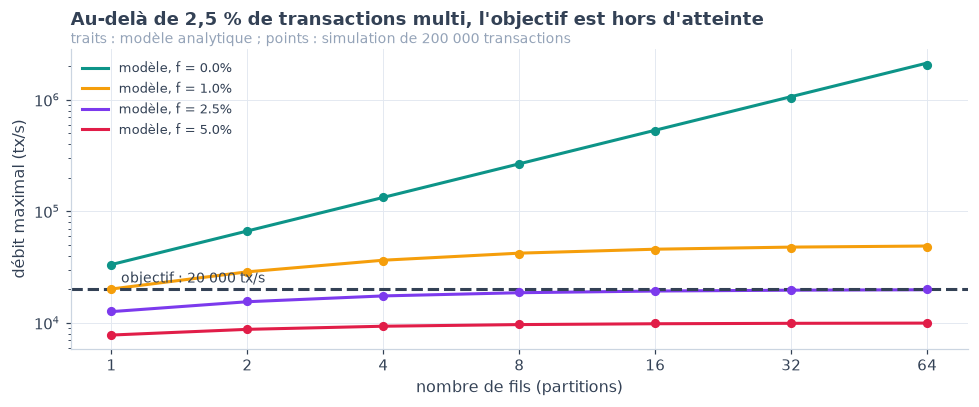

In [5]:
t_s, t_x, objectif = 30e-6, 2e-3, 20000


def debit_modele(n, f):
    return 1 / ((1 - f) * t_s / n + f * t_x)


def debit_simule(n, f, n_tx=200000, seed=0):
    g = np.random.default_rng(seed)
    multi = g.random(n_tx) < f
    occupation = np.zeros(n)
    np.add.at(occupation, g.integers(0, n, (~multi).sum()), t_s)
    occupation += multi.sum() * t_x            # chaque transaction multi occupe tous les fils
    return n_tx / occupation.max()


ns = [1, 2, 4, 8, 16, 32, 64]
fig, ax = plt.subplots(figsize=(9, 3.8))
for f, c in [(0.0, TEAL), (0.01, AMBER), (0.025, VIOLET), (0.05, ROSE)]:
    ax.plot(ns, [debit_modele(n, f) for n in ns], color=c, label=f"modèle, f = {f:.1%}")
    ax.scatter(ns, [debit_simule(n, f) for n in ns], color=c, s=25, zorder=3)
ax.axhline(objectif, color=SLATE, ls="--")
ax.text(1.05, objectif * 1.15, "objectif : 20 000 tx/s", fontsize=9, color=SLATE)
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xticks(ns); ax.set_xticklabels(ns)
ax.set_xlabel("nombre de fils (partitions)")
ax.set_ylabel("débit maximal (tx/s)")
ax.set_title("Au-delà de 2,5 % de transactions multi, l'objectif est hors d'atteinte")
subtitle(ax, "traits : modèle analytique ; points : simulation de 200 000 transactions")
ax.legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()

La simulation suit le modèle (elle est légèrement en dessous pour les grands $n$ : le fil
le plus chargé reçoit un peu plus que la moyenne, effet du hasard de l'affectation).
Avec $f = 2{,}5\,\%$, la courbe tend vers 20 000 sans jamais l'atteindre ; avec 5 %, le
plafond est à 10 000.

> **À retenir.** Pour l'exécution en série partitionnée, la fraction de transactions
> multi-partitions fixe un plafond indépendant du nombre de machines : $1/(f\,t_x)$.